# 09. 데이터셋 신뢰성과 NA 감사

전체 82,071,907개 정규화 시각을 DuckDB로 컬럼 선택 집계했습니다. 원본은 보존했으며 NA를 0으로 치환하지 않았습니다. 실제 실행 코드는 `src/dataset_audit45.py`, TTF 재검증은 `src/ttf_audit45.py`입니다. 기존 라벨을 완화할 이력 완전성 근거가 없어 ml_v2는 생성하지 않았습니다.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018"
import pandas as pd
from IPython.display import display,Markdown,Image
from src.improvement_common import OUT,read_json,configs
pd.set_option("display.max_columns",30)
print("실행 Python:",sys.executable)
print("저장된 실제 실험 결과를 읽습니다. 이 Notebook은 모델을 재학습하지 않습니다.")
def show(name):display(Image(filename=str(OUT/"figures"/(name+".png"))))


실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
저장된 실제 실험 결과를 읽습니다. 이 Notebook은 모델을 재학습하지 않습니다.


## 장비·Stage·유형별 미확인 라벨

,rows,positive,negative,unknown,NA 비율
fault_code,,,,,
any,82071907,49268,14377472,67645167,0.824218
f1,82071907,30026,27822831,54219050,0.660629
f2,82071907,10827,23882260,58178820,0.708876
f3,82071907,9088,19563070,62499749,0.761524


rows  positive  negative  unknown     NA 비율
Tool  fault_code                                                
01M01 any         3119431       861    631732  2486838  0.797209
      f1          3119431       471   1412620  1706340  0.547004
      f2          3119431       240   1377760  1741431  0.558253
      f3          3119431       150    631849  2487432  0.797399
01M02 any         5103087      9207   3133672  1960208  0.384122
...                   ...       ...       ...      ...       ...
10M01 f3          3163433       723    169154  2993556  0.946300
10M02 any         3752600        24         0  3752576  0.999994
      f1          3752600        24    844691  2907885  0.774899
      f2          3752600         0         0  3752600  1.000000
      f3          3752600         0         0  3752600  1.000000

[80 rows x 5 columns]

rows  positive  negative   unknown     NA 비율
state   fault_code                                                  
Stage=0 any          2531264      1951    589313   1940000  0.766416
        f1           2531264      1801   1639991    889472  0.351394
        f2           2531264       150   1525206   1005908  0.397394
        f3           2531264         0    699327   1831937  0.723724
Stage>0 any         79540643     47317  13788159  65705167  0.826058
        f1          79540643     28225  26182840  53329578  0.670470
        f2          79540643     10677  22357054  57172912  0.718789
        f3          79540643      9088  18863743  60667812  0.762727

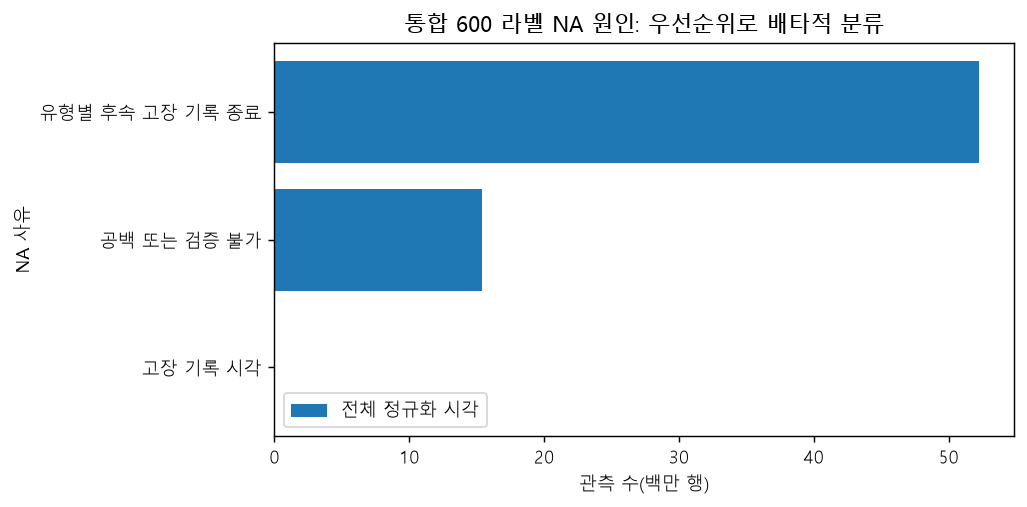

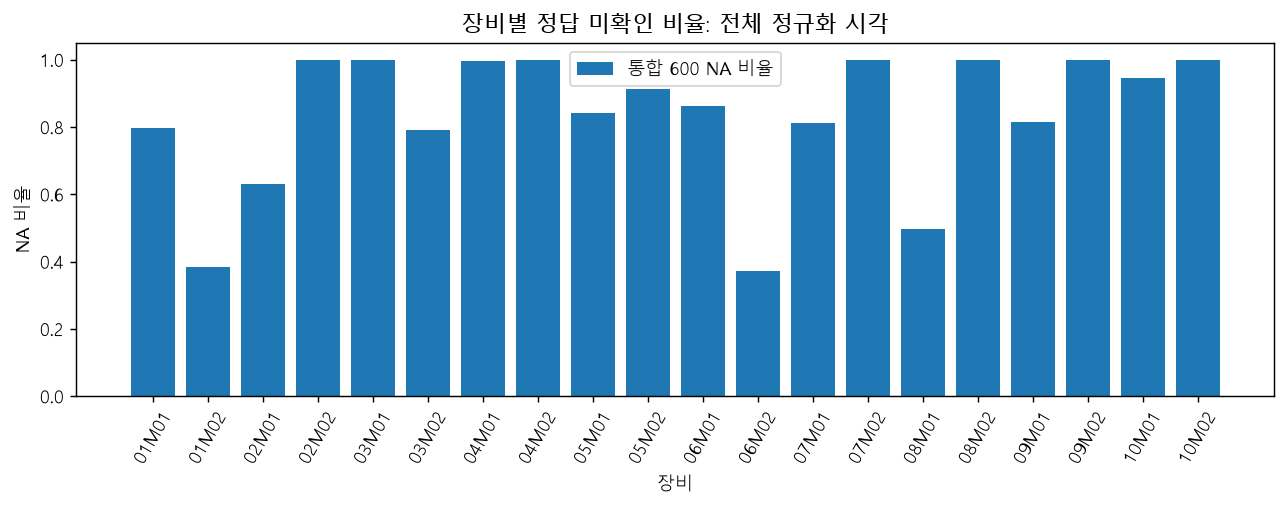

In [2]:
audit=pd.read_parquet(OUT/"na_audit.parquet")
for keys in [["fault_code"],["Tool","fault_code"],["state","fault_code"]]:
    stats=audit.groupby(keys)[["rows","positive","negative","unknown"]].sum()
    stats["NA 비율"]=stats.unknown/stats.rows
    display(stats)
show("na_reasons");show("na_tools")

후속 같은 유형 이벤트가 없는 구간은 고장 이력이 끝났다는 의미입니다. 고장이 없었다는 충분한 증거는 아니므로 정상 라벨로 확대하지 않았습니다. 통합 NA 원인은 배타적 우선순위 분류이며 공백과 이력 종료가 동시에 있을 수 있습니다.

In [3]:
display(pd.DataFrame(read_json(OUT/"ttf_recheck.json")["rows"]))
display(read_json(OUT/"label_policy.json"))
counts=pd.read_parquet(OUT/"cache_counts.parquet")
display(counts)
display(Markdown(f"확인 음성이 없는 장비는 **{int((counts.negative==0).sum())}대**입니다. 원래 training 포함 조건을 추론에서는 해제하여 {int(counts.rows.sum()):,}개의 준비된 anchor를 보존했습니다. NA는 학습 제외, 경보량에는 포함합니다."))

,Tool,location,fault_code,rows,nulls,mismatches
0,01M01,first,f1,4096,0,0
1,01M01,first,f2,4096,0,0
2,01M01,first,f3,4096,0,0
3,01M01,last,f1,1,1,0
4,01M01,last,f2,1,1,0
...,...,...,...,...,...,...
115,10M02,first,f2,4096,4096,0
116,10M02,first,f3,4096,4096,0
117,10M02,last,f1,1,1,0
118,10M02,last,f2,1,1,0


{'old': 'ml_v1',
 'labels_changed': 0,
 'new_dataset_created': False,
 'reason': 'TTF Null은 이후 동일 유형 기록이 없다는 뜻이며 고장 부재의 충분한 증거가 아니다. 공백을 건넌 양성·음성 확대도 근거 부족으로 보류한다.',
 'improvement': '라벨은 보존하고 NA 사유를 분리한다. 기존 training의 다른 타깃 알려짐 필터를 제거한 모든 feature_ready anchor를 추론 캐시에 보존한다. NA는 학습 제외, 경보량은 별도 측정한다.',
 'full_counts': [{'fault_code': 'any',
   'rows': 82071907,
   'positive': 49268,
   'negative': 14377472,
   'unknown': 67645167},
  {'fault_code': 'f1',
   'rows': 82071907,
   'positive': 30026,
   'negative': 27822831,
   'unknown': 54219050},
  {'fault_code': 'f2',
   'rows': 82071907,
   'positive': 10827,
   'negative': 23882260,
   'unknown': 58178820},
  {'fault_code': 'f3',
   'rows': 82071907,
   'positive': 9088,
   'negative': 19563070,
   'unknown': 62499749}],
 'cache_rows': 2331977}

,Tool,rows,positive,negative,unknown
0,01M01,95813,23,25603,70187
1,01M02,284516,537,171276,112703
2,02M01,96418,43,43586,52789
3,02M02,85672,30,0,85642
4,03M01,82739,88,0,82651
5,03M02,113367,246,22821,90300
6,04M01,106061,23,929,105109
7,04M02,247652,209,0,247443
8,05M01,84257,22,10929,73306
9,05M02,27384,10,2553,24821


확인 음성이 없는 장비는 **7대**입니다. 원래 training 포함 조건을 추론에서는 해제하여 2,331,977개의 준비된 anchor를 보존했습니다. NA는 학습 제외, 경보량에는 포함합니다.

## 실제 로컬 하드웨어

{'python': 'C:\\Users\\fl27\\anaconda3\\envs\\phm2018\\python.exe',
 'prefix': 'C:\\Users\\fl27\\anaconda3\\envs\\phm2018',
 'physical_cores': 8,
 'logical_cores': 16,
 'build': {'BUILTIN_PREFETCH_PRESENT': False,
  'CUDA_VERSION': [12, 9],
  'DEBUG': False,
  'MM_PREFETCH_PRESENT': True,
  'THRUST_VERSION': [2, 8, 2],
  'USE_CUDA': True,
  'USE_DLOPEN_NCCL': False,
  'USE_FEDERATED': False,
  'USE_NCCL': False,
  'USE_NVCOMP': False,
  'USE_OPENMP': True,
  'USE_RMM': False,
  'libxgboost': 'C:\\Users\\fl27\\anaconda3\\envs\\phm2018\\Lib\\site-packages\\xgboost\\lib\\xgboost.dll'},
 'median_seconds': {'cpu': 1.013816500082612, 'cuda': 0.7194431000389159},
 'selected_device': 'cuda',
 'cuda_warnings': []}

{'cpu_name': 'AMD Ryzen 7 6800H with Radeon Graphics',
 'peak_system_gpu_mib': 1306.0,
 'min_available_ram_gib': 17.341529846191406,
 'note': 'GPU 사용량은 다른 화면·프로세스를 포함한 장치 전체 값이다. CPU 모델명 조회 CIM은 권한 제한으로 실패했고 레지스트리 읽기로 확인했다.'}

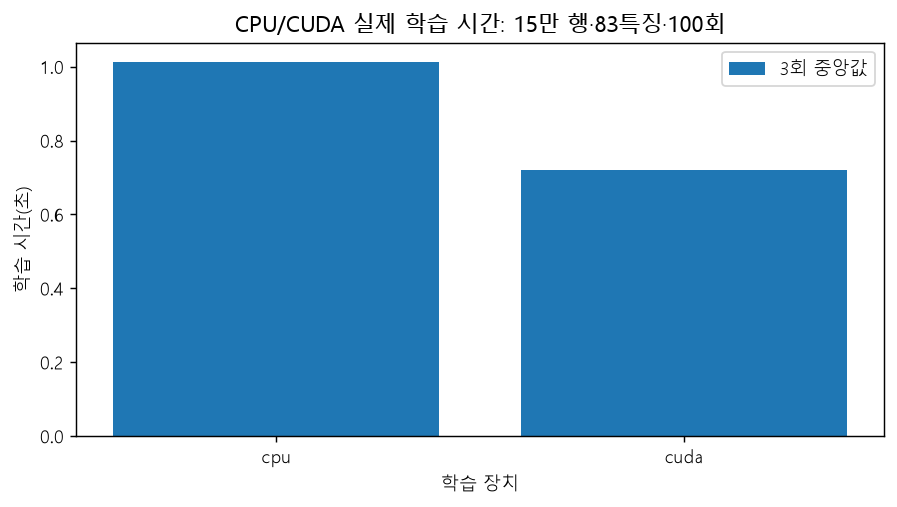

In [4]:
hardware=read_json(OUT/"hardware.json")
display({k:hardware[k] for k in ["python","prefix","physical_cores","logical_cores","build","median_seconds","selected_device","cuda_warnings"]})
display(read_json(OUT/"hardware_supplement.json"));show("hardware")

실제 Booster의 cuda:0과 CPU/GPU 시간 차이를 확인했습니다. GPU 6GB 한계를 고려해 학습을 순차 실행하고 4 CPU 스레드를 사용합니다. 같은 설정의 속도 비교이며 CPU/GPU 모델 성능이 같다는 검증은 아닙니다. 기본 python3 커널의 이름만 믿지 않고 아래 실행 사양에 phm2018 절대 경로를 지정했습니다.